# Changeover Guard — operator diagnostic system

This notebook investigates all **27 October 29 vials**, retaining sensor rejects,
missing references and uncertain causes. It compares overhead tank initialization
with same-camera, held-out-run vial references, then explains the available
recipe-sequence, camera-quality and recovery evidence to an operator.

**Kept:** the existing timestamp/hash audit, the stale vial-9 check, dark-channel
and uneven-patch rejection, blackout labels, requested-volume provenance and
recipe-run tracking from `transition_analysis.ipynb` and its reusable modules.

**Refactored:** both baseline methods use the same usable cohort, the same
threshold and whole-run holdouts. Same-run tails cannot grade themselves. Missing
T200 targets stay missing. Empty score groups print coverage and reasons rather
than an unexplained blank chart. The earlier pre-fill comparison mixed reference
rules and could select the previous filled vial; **no pre-fill subtraction is
performed here**. Pre-fill inspection is suggested only as operator follow-up.

Attribution is **retrospective and exploratory**: later vials may support a
recovery trend, stable tails are surrogate clean references, and color agreement
cannot prove chemical purity. No camera repeatability or calibrated vial-fill
measurements have been supplied. Production release remains `PENDING`.

Run from the repository with `uv sync --locked --group analysis`, then select its
Python environment in Jupyter. All outputs go into a fresh ignored directory;
the previous notebooks and their saved analyses are preserved.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import HTML, Image, display

from changeover_guard.diagnostic_baselines import OCT29_TANK_ROIS
from changeover_guard.diagnostic_workflow import audit_notebooks, run_operator_workflow

ROOT = Path.cwd().resolve()
if not (ROOT / 'pyproject.toml').is_file():
    ROOT = ROOT.parent
assert (ROOT / 'pyproject.toml').is_file(), 'Start in the repository or notebooks directory.'
pd.set_option('display.max_colwidth', 160)
TANK_IMAGE = ROOT / 'data/10_29_26/top_view/images/tank_top_level_10_29_26.jpg'
# Normalized rectangles are specific to the 4:3 photo supplied for this collection.
# Adjust these if ROI verification shows glare, hardware or a different view.
TANK_ROIS = dict(OCT29_TANK_ROIS)
display(pd.DataFrame(TANK_ROIS, index=['left', 'top', 'right', 'bottom']).T)


,left,top,right,bottom
T100,0.220,0.488,0.285,0.528
T200,0.415,0.484,0.480,0.524
T400,0.875,0.487,0.930,0.531


## 1. Audit all existing notebooks

The table below reads each `.ipynb` source, records its imports and source hash,
and documents reused behavior and limitations. The detailed October 29 assessment
is `docs/dataset_assessment_10_29_26.md`.

Important clock lesson: the roughly 30-second discrepancy observed at playback
second 140 is **not assumed to be a constant offset**. Wall labels and MP4 seconds
are different domains here; source selection uses audited timestamped stills.
The legacy adapters now measure color, compare against clean color and provide
investigation advice, but abstain without validated model/fill evidence.

In [2]:
audit = audit_notebooks(ROOT)
display(audit[['notebook', 'cells', 'code_cells', 'kept', 'improved_or_not_used']])


,notebook,cells,code_cells,kept,improved_or_not_used
0,notebooks/operator_diagnostic_system.ipynb,16,8,Controlled baseline coverage and evidence-aware operator explanations.,"Abstain when references, measured fill, previous signatures or camera evidence are unavailable."
1,notebooks/paired_empty_vial_transition_analysis.ipynb,15,8,Reuse visual ROI/source review and explicit missing-reference reporting.,No pre-fill subtraction. Use identical holdouts and proxy groups; inspect pre-fill only as operator follow-up.
2,notebooks/transition_analysis.ipynb,19,10,"Reuse clock/hash audit, rejected rows, same-recipe runs, camera and model evidence gates.",Hold out the whole evaluated run; never substitute the same run's tail for an independent target.


## 2. Supply the original overhead tank image

If the JPG exists at the configured path, it is used directly. Otherwise upload
the original image with the control below, then rerun from Section 3. Images
visible in chat are not automatically copied into the execution filesystem.
No generated image or hand-estimated color is substituted for this photograph.

Physical vessel order is T100, T200, **T300 out of service**, T400. The explicit
liquid ROIs cover T100/T200/T400 only. This image supplies color signatures, not
calibrated tank concentration or liquid-level measurements.

In [3]:
if not TANK_IMAGE.is_file():
    import ipywidgets as widgets

    from changeover_guard.baseline import decode_image

    tank_upload = widgets.FileUpload(accept='.jpg,.jpeg,.png', multiple=False)
    upload_status = widgets.Output()

    def save_tank_upload(change):
        if not tank_upload.value:
            return
        upload = tank_upload.value[0]
        payload = bytes(upload['content'])
        with upload_status:
            upload_status.clear_output()
            try:
                image = decode_image(payload)
                TANK_IMAGE.parent.mkdir(parents=True, exist_ok=True)
                TANK_IMAGE.write_bytes(payload)
                print('Saved original tank image:', TANK_IMAGE.relative_to(ROOT))
                print('Image dimensions:', image.shape[1], 'x', image.shape[0])
                print('Rerun Section 3 onward to compare both baseline methods.')
            except ValueError as exc:
                print('Image rejected:', exc)

    tank_upload.observe(save_tank_upload, names='value')
    display(tank_upload, upload_status)
    print('Approach A stays pending until the original image is saved/uploaded.')
else:
    print('Using:', TANK_IMAGE.relative_to(ROOT))


FileUpload(value=(), accept='.jpg,.jpeg,.png', description='Upload')

Output()

Approach A stays pending until the original image is saved/uploaded.


## 3. Re-measure the October 29 sequence and review exact ROIs

The workflow runs from raw labels/images, using the established quality gates.
It does not reload a prior successful fit. In the supplied collection, 26 images
exist for 27 vials; 16 readings pass the original checks. Rejects remain in the
sequence and do not receive numerical color scores.

The following figures show the tank liquid patches and all selected vial source
frames. Clock ages, image hashes and rejection flags are exported for review.

status                                                                                                                                                                                 measured
vials                                                                                                                                                                                        27
quality_eligible_vials                                                                                                                                                                       16
diagnostic_states                                                                                                                     {'evidence_pending': 16, 'measurement_sensor_reject': 11}
color_assessments                                                                                   {'unassessable': 17, 'outside_reference_exploratory': 7, 'within_reference_exploratory': 3}
tank_image_status                       

,session_id,timing,frame_labels,video_container_duration_s,last_labeled_end_s,label_clock_exceeds_container,measurement_source
0,10_29_26,"{'schema': 'wall_clock', 'video_origin': '2026-10-30T02:02:55.390000', 'origin_source': 'frame_timestamp_minus_video_s'}","{'status': 'audited', 'frames': 1187, 'labeled_vials': 26, 'expected_images': 1187, 'available_images': 1187, 'missing_image_examples': [], 'warning': 'Revi...",1956.3,2128.61,True,timestamped_stills


clipped_dark_channels       8
label_status_not_ok         2
uneven_liquid_patch         1
stale_camera_frame          1
unobservable_vial_window    1
Name: flagged_vials, dtype: int64

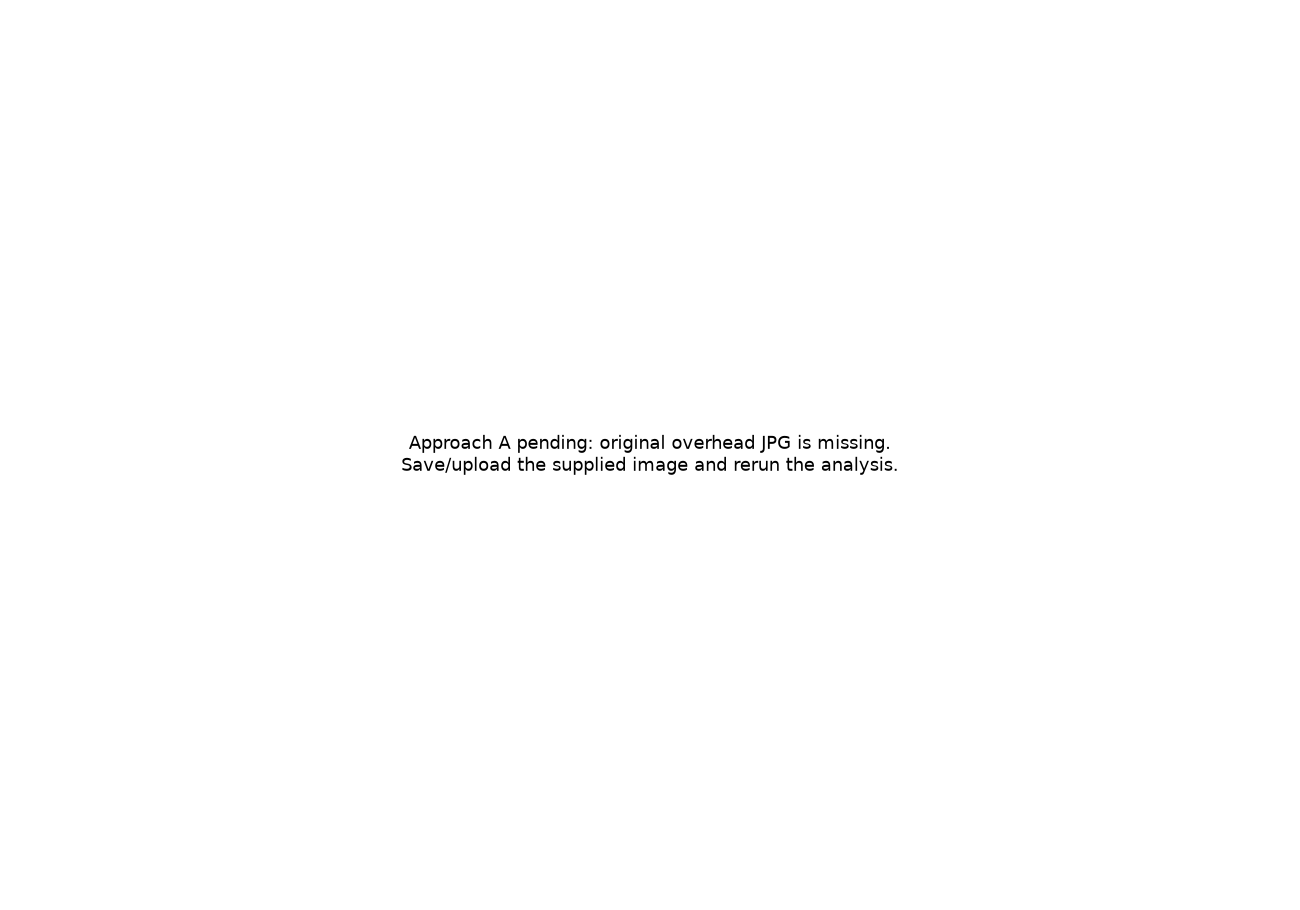

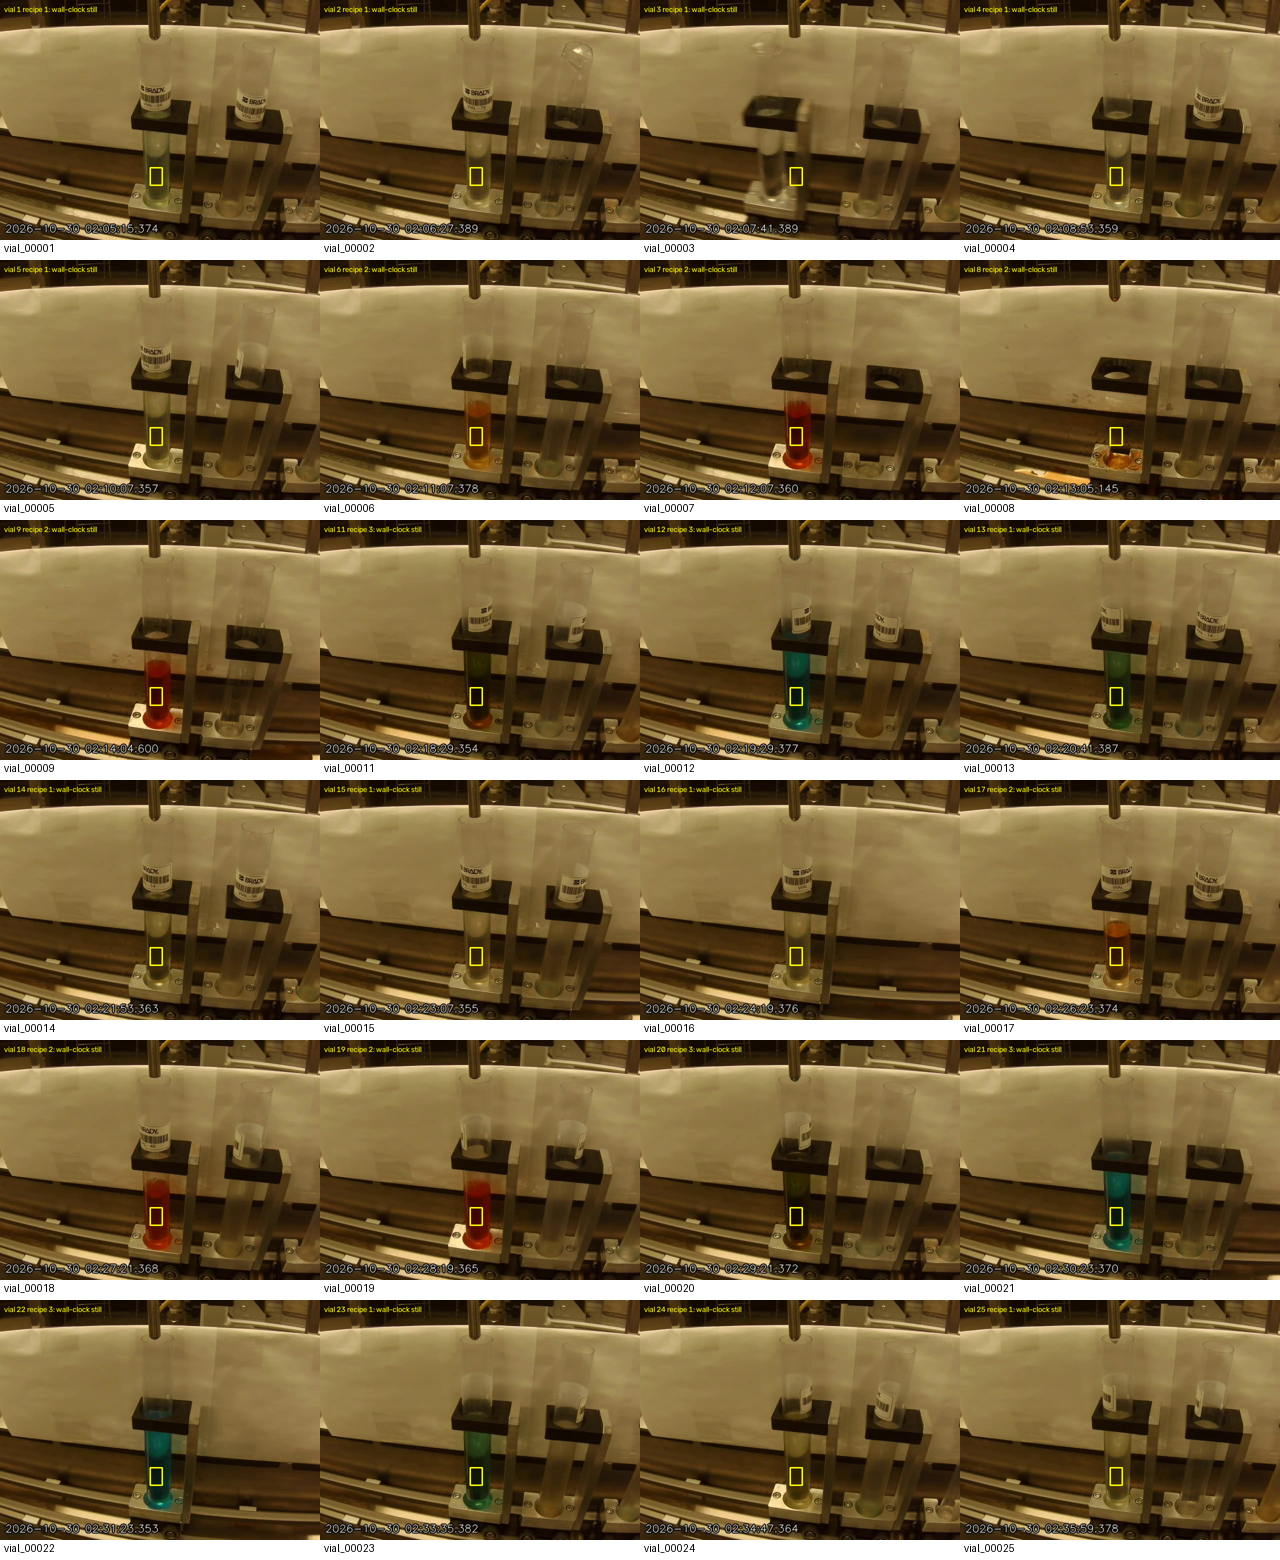

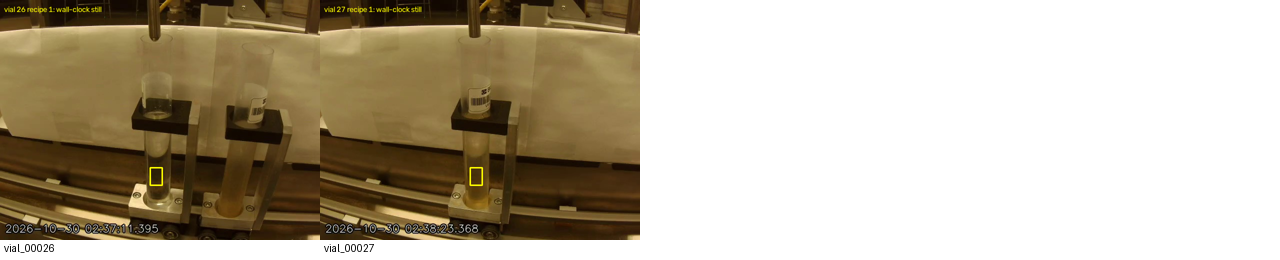

,vial,recipe_id,run_id,r,g,b,usable,source_clock_verified,source_timestamp_age_s,quality_flags,volume_source
0,1,1,10_29_26/run1,54.0,45.0,16.0,True,True,0.016,,requested_proxy
1,2,1,10_29_26/run1,64.0,45.0,16.0,True,True,0.001,,requested_proxy
2,3,1,10_29_26/run1,52.0,37.0,12.0,False,True,0.001,uneven_liquid_patch,requested_proxy
3,4,1,10_29_26/run1,59.0,44.0,15.0,True,True,0.031,,requested_proxy
4,5,1,10_29_26/run1,60.0,45.0,14.0,True,True,0.033,,requested_proxy
5,6,2,10_29_26/run2,64.0,30.0,0.0,False,True,0.012,clipped_dark_channels,requested_proxy
6,7,2,10_29_26/run2,57.0,9.0,0.0,False,True,0.030,clipped_dark_channels,requested_proxy
7,8,2,10_29_26/run2,56.0,34.0,6.0,False,True,0.245,label_status_not_ok,requested_proxy
8,9,2,10_29_26/run2,57.0,7.0,0.0,False,False,6.790,clipped_dark_channels;stale_camera_frame,requested_proxy
9,10,2,10_29_26/run2,NaN,NaN,NaN,False,False,NaN,label_status_not_ok;unobservable_vial_window,requested_proxy


In [4]:
result = run_operator_workflow(ROOT, tank_image=TANK_IMAGE, tank_rois=TANK_ROIS)
OUTPUT = result['output_dir']
measured = result['measurement_result']
measurements = measured['measurements']
display(pd.Series(result['summary']))
display(pd.DataFrame(measured['report'].get('label_audits', [])))
display(pd.Series(measured['report'].get('measurement_quality_flags', {}), name='flagged_vials'))
display(Image(filename=str(OUTPUT / 'tank_roi_verification.png'), width=950))
for contact in sorted(OUTPUT.glob('alignment_roi_*.png')):
    display(Image(filename=str(contact), width=1150))
if not measurements.empty:
    display(measurements[['vial', 'recipe_id', 'run_id', 'r', 'g', 'b', 'usable',
                          'source_clock_verified', 'source_timestamp_age_s',
                          'quality_flags', 'volume_source']])


## 4. Controlled A vs B initialization experiment

**A — overhead tank camera:** convert pure-tank RGB to linear RGB, compute signed
effective optical density relative to T100, and combine by recipe volume
fractions. Pure recipes reproduce their measured tank endpoint. This candidate
has **no learned camera-transfer or path-length calibration**. Total mL effects
are unestimated; tank RGB is not silently certified as expected vial RGB.

**B — vial camera:** select stable two-vial tails, then build the target from
matching recipe/composition tails in **other runs only**. No self-target fallback
is allowed. Future runs can supply references, so this is retrospective analysis.

Both use the same 16 quality-eligible vials and **ΔE00 < 2.2**. Comparative metrics
use the **intersection of scored vial IDs**. All rows, including unscored ones,
remain in `baseline_scores.csv` with reasons and reference identities.

First changeover vials and the last two vials of runs are **proxy groups**, not
independent clean/contaminated labels. Evaluation late-vial membership is fixed
by position, not by low measured error. Balanced proxy accuracy is the average
of first-vial alert rate and late-vial match rate; it is not production accuracy.
Selection requires both proxy groups in common coverage. Otherwise B can be
used provisionally, and the notebook explicitly declares no head-to-head winner.

,method,scope,eligible_vials,scored_vials,first_proxy_n,settled_proxy_n,settled_median_delta_e,first_median_delta_e,proxy_separation_delta_e,balanced_proxy_accuracy,status
0,A_tank_camera,available_coverage,16,0,0,0,NaN,NaN,NaN,NaN,insufficient_proxy_groups
1,A_tank_camera,common_holdout,16,0,0,0,NaN,NaN,NaN,NaN,insufficient_proxy_groups
2,B_vial_camera,available_coverage,16,10,2,4,3.279992,15.085293,11.805301,0.625,exploratory_proxy_comparison
3,B_vial_camera,common_holdout,16,0,0,0,NaN,NaN,NaN,NaN,insufficient_proxy_groups


primary_method                                                                                                                          B_vial_camera
status                                                                                                                               provisional_only
reason                    Use available in-camera references. No defensible head-to-head winner: missing A input or insufficient common proxy groups.
quality_eligible_vials                                                                                                                             16
common_scored_vials                                                                                                                                 0
threshold                                                                                                                                         2.2
holdout                                                                                             

,vial,recipe_id,method,trusted,evaluation_role,reference_available,delta_e,paired_comparison,reference_runs,reference_reason
0,1,1,A_tank_camera,True,followup,False,NaN,False,[],Save the original tank JPG at this path or upload it in the notebook.
1,1,1,B_vial_camera,True,followup,False,NaN,False,[],No usable stable tail outside the held-out run
2,2,1,A_tank_camera,True,followup,False,NaN,False,[],Save the original tank JPG at this path or upload it in the notebook.
3,2,1,B_vial_camera,True,followup,False,NaN,False,[],No usable stable tail outside the held-out run
4,3,1,A_tank_camera,False,followup,False,NaN,False,[],Save the original tank JPG at this path or upload it in the notebook.
5,3,1,B_vial_camera,False,followup,False,NaN,False,[],No usable stable tail outside the held-out run
6,4,1,A_tank_camera,True,late_run_proxy,False,NaN,False,[],Save the original tank JPG at this path or upload it in the notebook.
7,4,1,B_vial_camera,True,late_run_proxy,False,NaN,False,[],No usable stable tail outside the held-out run
8,5,1,A_tank_camera,True,late_run_proxy,False,NaN,False,[],Save the original tank JPG at this path or upload it in the notebook.
9,5,1,B_vial_camera,True,late_run_proxy,False,NaN,False,[],No usable stable tail outside the held-out run


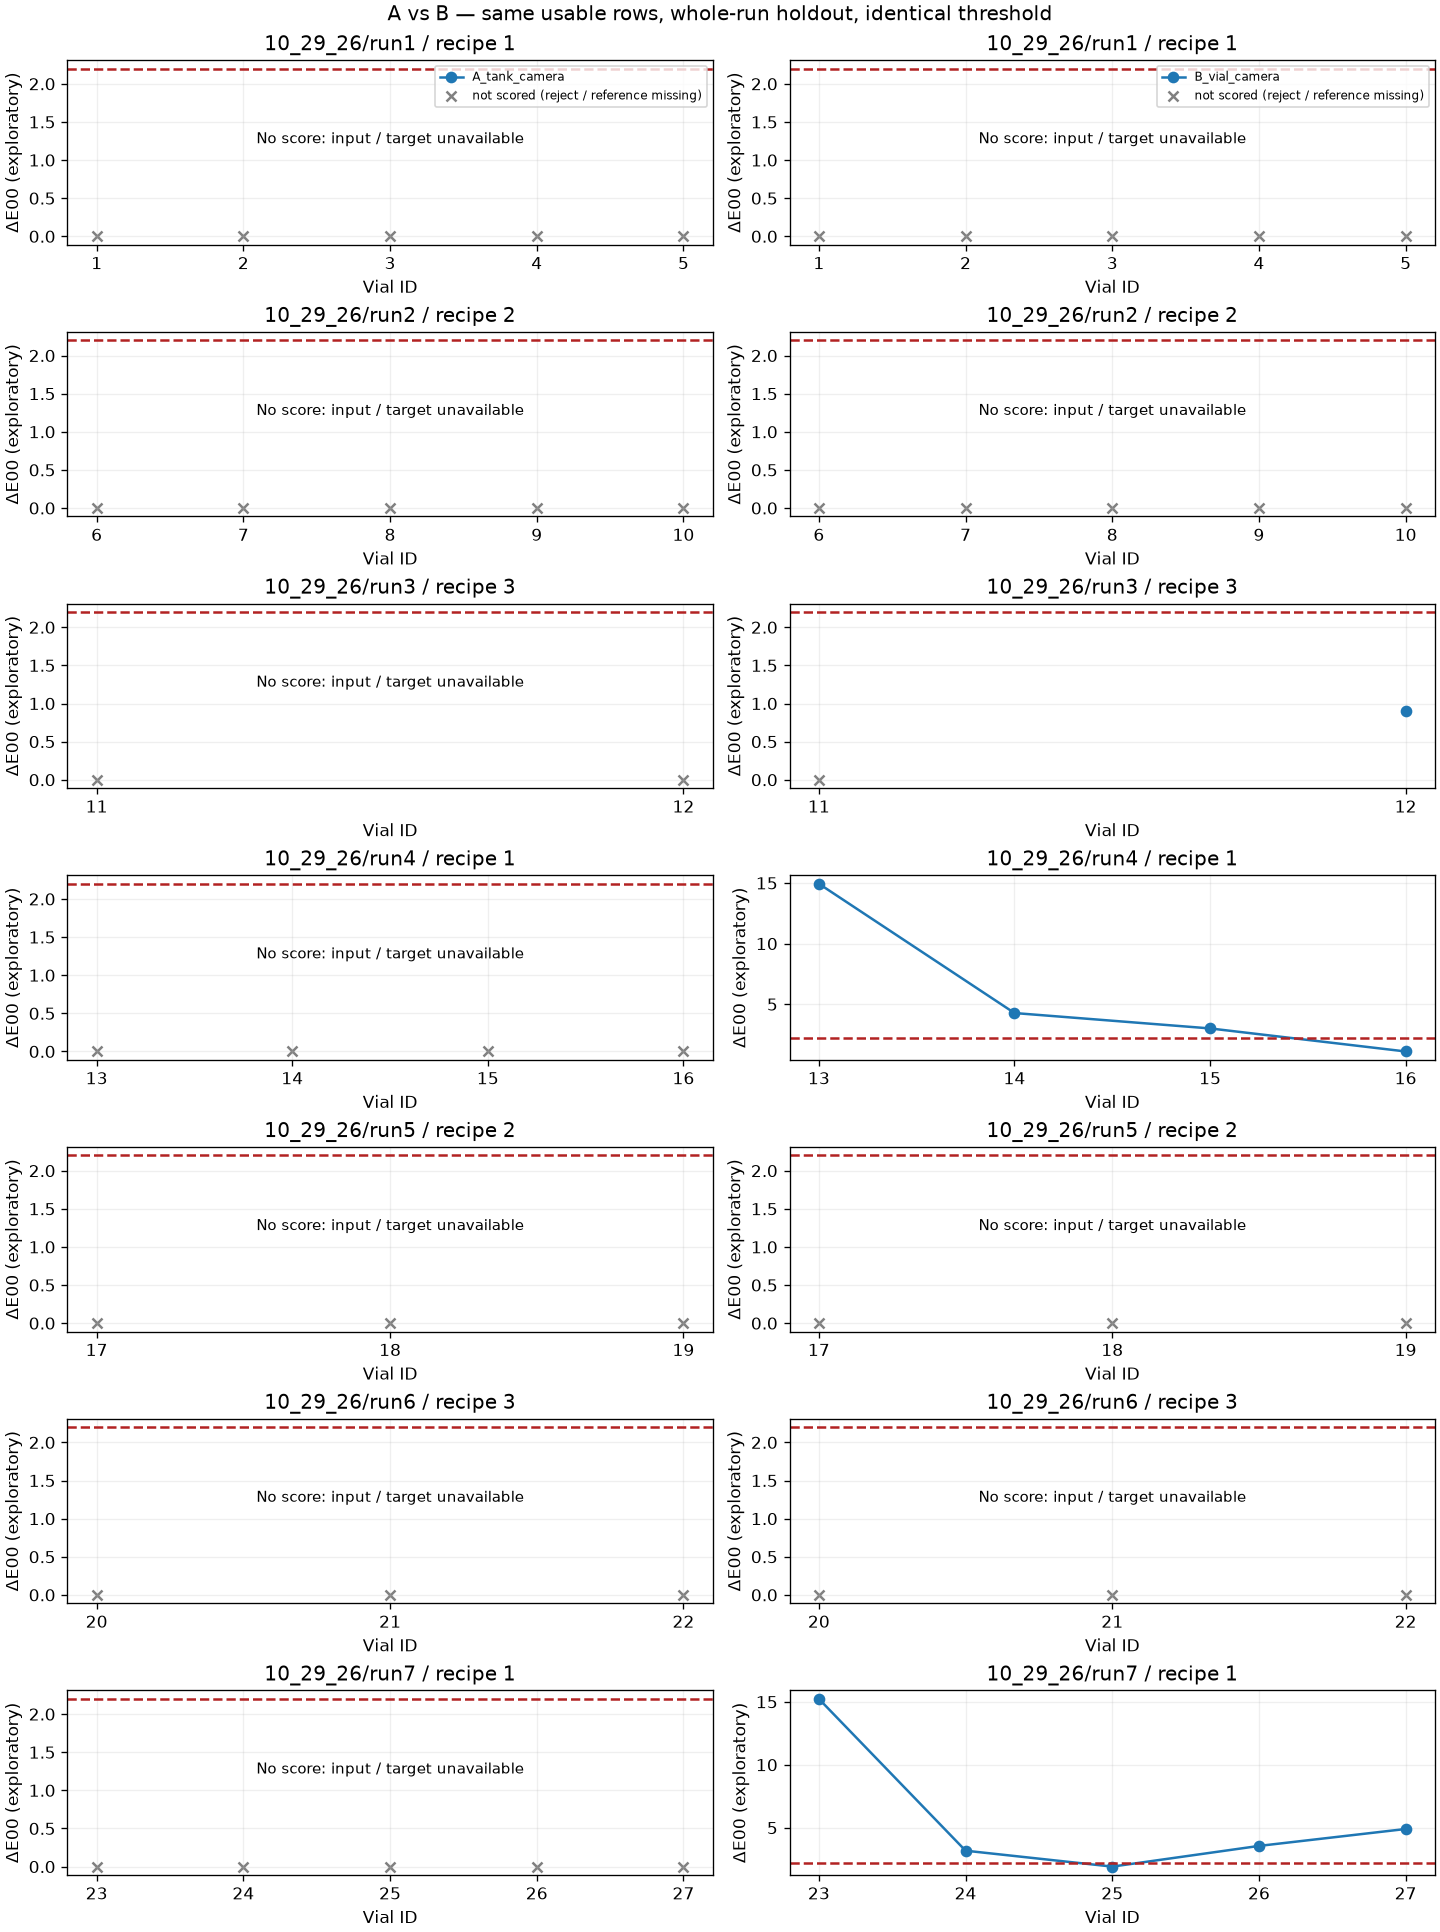

In [5]:
benchmark = result['benchmark']
display(benchmark['metrics'])
display(pd.Series(benchmark['selection']))
if not benchmark['scores'].empty:
    display(benchmark['scores'][['vial', 'recipe_id', 'method', 'trusted',
        'evaluation_role', 'reference_available', 'delta_e', 'paired_comparison',
        'reference_runs', 'reference_reason']])
comparison_plot = OUTPUT / 'baseline_comparison.png'
if comparison_plot.is_file():
    display(Image(filename=str(comparison_plot), width=1150))


## 5. Operator diagnostic and attribution engine

The engine inspects every label row in sequence, using the selected baseline.

| State | Required observation and operator interpretation |
|---|---|
| Measurement / sensor reject | Clipping, stale/unverified timing, uneven patch, missing frame or operator-error label. Reacquire trustworthy evidence before judging mixture. |
| Changeover carryover suspected | A recipe change, an identifiable previous-to-current color trajectory, and decreasing error across at least three consecutive usable run observations. This uses later observations and is a hypothesis. |
| Persistent tank / recipe / fill fault suspected | Persistent observed deviation without decay, an unrequested in-camera tank signature, a verified tank-state alert, or independently calibrated abnormal fill. Inspect hardware and recipe; no automatic root-cause proof. |
| In-spec / clean production | Within tolerance **and** validated independent reference and camera evidence. An exploratory match alone cannot release production. |
| Evidence pending | Missing reference, ambiguous trajectory or incomplete calibration. The report records the available color assessment and an explicit next investigation. |

Requested recipe mL is not a fill measurement. A static tank photograph does not
prove valve malfunction or abnormal tank level. No expected clearance volume is
invented. A Lab trajectory weight is a color-coordinate parameter, not a residual
chemical fraction. No confidence interval is reported without camera evidence.

**Pre-fill policy:** raw filled-vial colors are used throughout. If a vial is
outside tolerance, rejected or lacks sufficient evidence, the operator may be
advised to inspect/capture the same vial before dispensing. There is no automatic
pre-fill subtraction, normalization or correction in this notebook.

In [6]:
operator_report = result['operator_report']
if operator_report.empty:
    print('No measurements: inspect the missing-input audit before running diagnostics.')
else:
    display(operator_report[['vial', 'recipe_id', 'diagnostic_label', 'delta_e',
        'color_assessment', 'fill_status', 'production_status', 'explanation',
        'recommended_action', 'prefill_inspection_suggestion']])
    display(operator_report[['vial', 'run_id', 'run_decay_supported',
        'trajectory_supported', 'trajectory_residual_delta_e', 'prior_color_weight',
        'trend_usable_prefix_vials', 'evidence']])


,vial,recipe_id,diagnostic_label,delta_e,color_assessment,fill_status,production_status,explanation,recommended_action,prefill_inspection_suggestion
0,1,1,Evidence pending,NaN,unassessable,not_measured,PENDING,No independent clean reference is available; chemical mixture cannot be verified.,Collect clean same-camera controls for this recipe; do not substitute an unmapped tank color.,"Inspect this vial's glass, position and reflections. If available, review an image of the same vial before dispensing, or collect a pre-fill image on a repe..."
1,2,1,Evidence pending,NaN,unassessable,not_measured,PENDING,No independent clean reference is available; chemical mixture cannot be verified.,Collect clean same-camera controls for this recipe; do not substitute an unmapped tank color.,"Inspect this vial's glass, position and reflections. If available, review an image of the same vial before dispensing, or collect a pre-fill image on a repe..."
2,3,1,Measurement / sensor reject,NaN,unassessable,not_measured,PENDING,Cannot verify chemical mixture: uneven_liquid_patch.,"Inspect the camera, exposure, vial position and clock alignment; reacquire a trustworthy frame.","Inspect this vial's glass, position and reflections. If available, review an image of the same vial before dispensing, or collect a pre-fill image on a repe..."
3,4,1,Evidence pending,NaN,unassessable,not_measured,PENDING,No independent clean reference is available; chemical mixture cannot be verified.,Collect clean same-camera controls for this recipe; do not substitute an unmapped tank color.,"Inspect this vial's glass, position and reflections. If available, review an image of the same vial before dispensing, or collect a pre-fill image on a repe..."
4,5,1,Evidence pending,NaN,unassessable,not_measured,PENDING,No independent clean reference is available; chemical mixture cannot be verified.,Collect clean same-camera controls for this recipe; do not substitute an unmapped tank color.,"Inspect this vial's glass, position and reflections. If available, review an image of the same vial before dispensing, or collect a pre-fill image on a repe..."
5,6,2,Measurement / sensor reject,NaN,unassessable,not_measured,PENDING,Cannot verify chemical mixture: clipped_dark_channels.,"Inspect the camera, exposure, vial position and clock alignment; reacquire a trustworthy frame.","Inspect this vial's glass, position and reflections. If available, review an image of the same vial before dispensing, or collect a pre-fill image on a repe..."
6,7,2,Measurement / sensor reject,NaN,unassessable,not_measured,PENDING,Cannot verify chemical mixture: clipped_dark_channels.,"Inspect the camera, exposure, vial position and clock alignment; reacquire a trustworthy frame.","Inspect this vial's glass, position and reflections. If available, review an image of the same vial before dispensing, or collect a pre-fill image on a repe..."
7,8,2,Measurement / sensor reject,NaN,unassessable,not_measured,PENDING,Cannot verify chemical mixture: label_status_not_ok.,"Inspect the camera, exposure, vial position and clock alignment; reacquire a trustworthy frame.","Inspect this vial's glass, position and reflections. If available, review an image of the same vial before dispensing, or collect a pre-fill image on a repe..."
8,9,2,Measurement / sensor reject,NaN,unassessable,not_measured,PENDING,Cannot verify chemical mixture: clipped_dark_channels;stale_camera_frame;source_clock_unverified. Camera frame is stale by 6.79 seconds.,"Inspect the camera, exposure, vial position and clock alignment; reacquire a trustworthy frame.","Inspect this vial's glass, position and reflections. If available, review an image of the same vial before dispensing, or collect a pre-fill image on a repe..."
9,10,2,Measurement / sensor reject,NaN,unassessable,not_measured,PENDING,Cannot verify chemical mixture: label_status_not_ok;unobservable_vial_window;source_clock_unverified;color_not_observed.,"Inspect the camera, exposure, vial position and

,vial,run_id,run_decay_supported,trajectory_supported,trajectory_residual_delta_e,prior_color_weight,trend_usable_prefix_vials,evidence
0,1,10_29_26/run1,False,False,NaN,NaN,0,reference_missing
1,2,10_29_26/run1,False,False,NaN,NaN,0,reference_missing
2,3,10_29_26/run1,False,False,NaN,NaN,0,measurement_gate_failed
3,4,10_29_26/run1,False,False,NaN,NaN,0,reference_missing
4,5,10_29_26/run1,False,False,NaN,NaN,0,reference_missing
5,6,10_29_26/run2,False,False,NaN,NaN,0,measurement_gate_failed
6,7,10_29_26/run2,False,False,NaN,NaN,0,measurement_gate_failed
7,8,10_29_26/run2,False,False,NaN,NaN,0,measurement_gate_failed
8,9,10_29_26/run2,False,False,NaN,NaN,0,measurement_gate_failed
9,10,10_29_26/run2,False,False,NaN,NaN,0,measurement_gate_failed


## 6. All-vial timeline and filterable operator dashboard

An x at zero identifies a sensor reject; an empty square marks a missing
reference. Neither means zero color error. Missing scores create gaps in the
ΔE curve. The state strip keeps every vial
visible, including the blackout. The exported HTML dashboard can be opened
without Jupyter and filters explanations by attribution state.

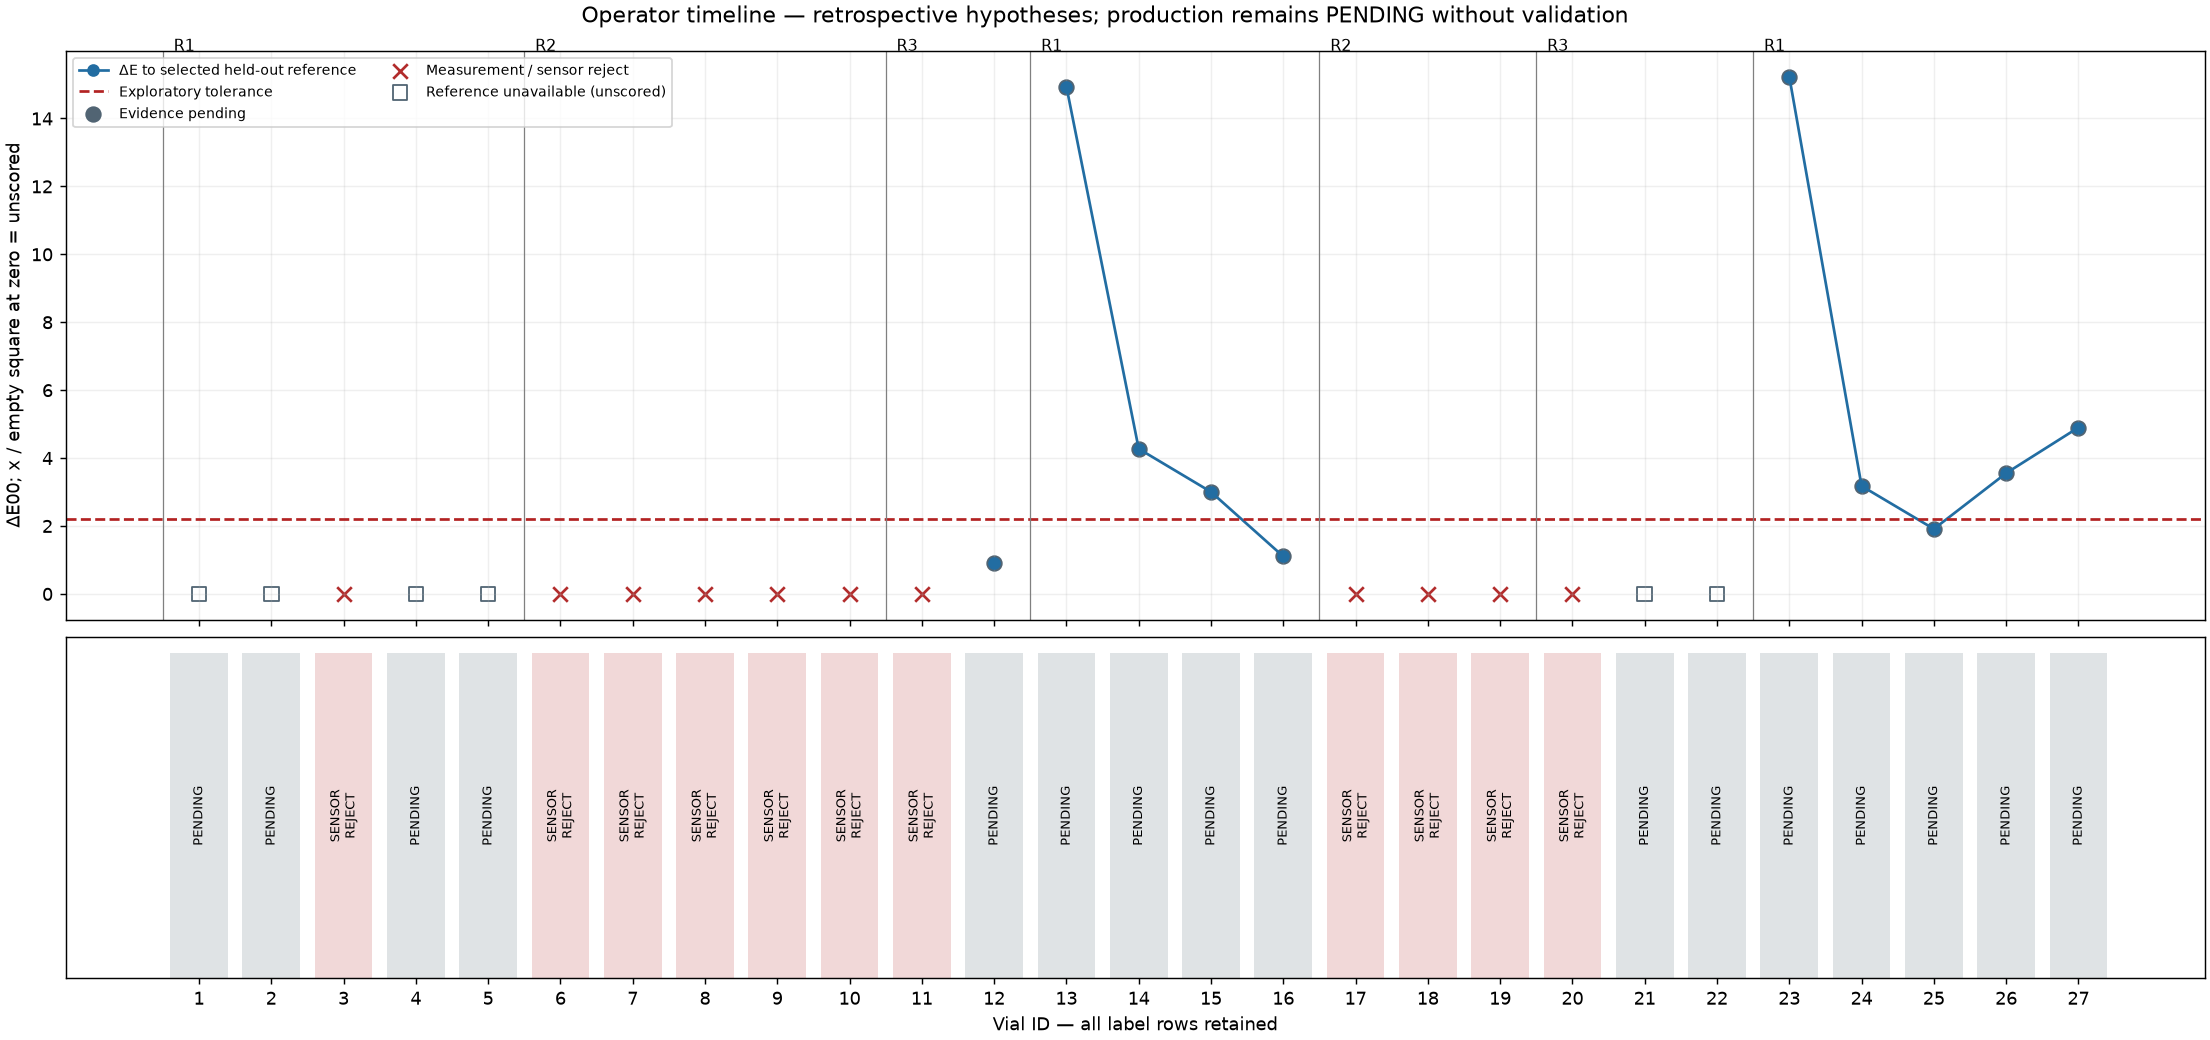

vial,recipe_id,diagnostic_label,delta_e,color_assessment,fill_status,production_status,explanation,recommended_action,prefill_inspection_suggestion
1,1,Evidence pending,,unassessable,not_measured,PENDING,No independent clean reference is available; chemical mixture cannot be verified.,Collect clean same-camera controls for this recipe; do not substitute an unmapped tank color.,"Inspect this vial's glass, position and reflections. If available, review an image of the same vial before dispensing, or collect a pre-fill image on a repeat. Use it as a visual diagnostic; do not subtract it from the measured color."
2,1,Evidence pending,,unassessable,not_measured,PENDING,No independent clean reference is available; chemical mixture cannot be verified.,Collect clean same-camera controls for this recipe; do not substitute an unmapped tank color.,"Inspect this vial's glass, position and reflections. If available, review an image of the same vial before dispensing, or collect a pre-fill image on a repeat. Use it as a visual diagnostic; do not subtract it from the measured color."
3,1,Measurement / sensor reject,,unassessable,not_measured,PENDING,Cannot verify chemical mixture: uneven_liquid_patch.,"Inspect the camera, exposure, vial position and clock alignment; reacquire a trustworthy frame.","Inspect this vial's glass, position and reflections. If available, review an image of the same vial before dispensing, or collect a pre-fill image on a repeat. Use it as a visual diagnostic; do not subtract it from the measured color."
4,1,Evidence pending,,unassessable,not_measured,PENDING,No independent clean reference is available; chemical mixture cannot be verified.,Collect clean same-camera controls for this recipe; do not substitute an unmapped tank color.,"Inspect this vial's glass, position and reflections. If available, review an image of the same vial before dispensing, or collect a pre-fill image on a repeat. Use it as a visual diagnostic; do not subtract it from the measured color."
5,1,Evidence pending,,unassessable,not_measured,PENDING,No independent clean reference is available; chemical mixture cannot be verified.,Collect clean same-camera controls for this recipe; do not substitute an unmapped tank color.,"Inspect this vial's glass, position and reflections. If available, review an image of the same vial before dispensing, or collect a pre-fill image on a repeat. Use it as a visual diagnostic; do not subtract it from the measured color."
6,2,Measurement / sensor reject,,unassessable,not_measured,PENDING,Cannot verify chemical mixture: clipped_dark_channels.,"Inspect the camera, exposure, vial position and clock alignment; reacquire a trustworthy frame.","Inspect this vial's glass, position and reflections. If available, review an image of the same vial before dispensing, or collect a pre-fill image on a repeat. Use it as a visual diagnostic; do not subtract it from the measured color."
7,2,Measurement / sensor reject,,unassessable,not_measured,PENDING,Cannot verify chemical mixture: clipped_dark_channels.,"Inspect the camera, exposure, vial position and clock alignment; reacquire a trustworthy frame.","Inspect this vial's glass, position and reflections. If available, review an image of the same vial before dispensing, or collect a pre-fill image on a repeat. Use it as a visual diagnostic; do not subtract it from the measured color."
8,2,Measurement / sensor reject,,unassessable,not_measured,PENDING,Cannot verify chemical mixture: label_status_not_ok.,"Inspect the camera, exposure, vial position and clock alignment; reacquire a trustworthy frame.","Inspect this vial's glass, position and reflections. If available, review an image of the same vial before dispensing, or collect a pre-fill image on a repeat. Use it as a visual diagnostic; do not subtract it from the measured color."
9,2,Measurement / sensor reject,,unassessable,not_measured,PENDING,Cannot verify chemical mixture: clipped_dark_channels;stale_camera_frame;source_clock
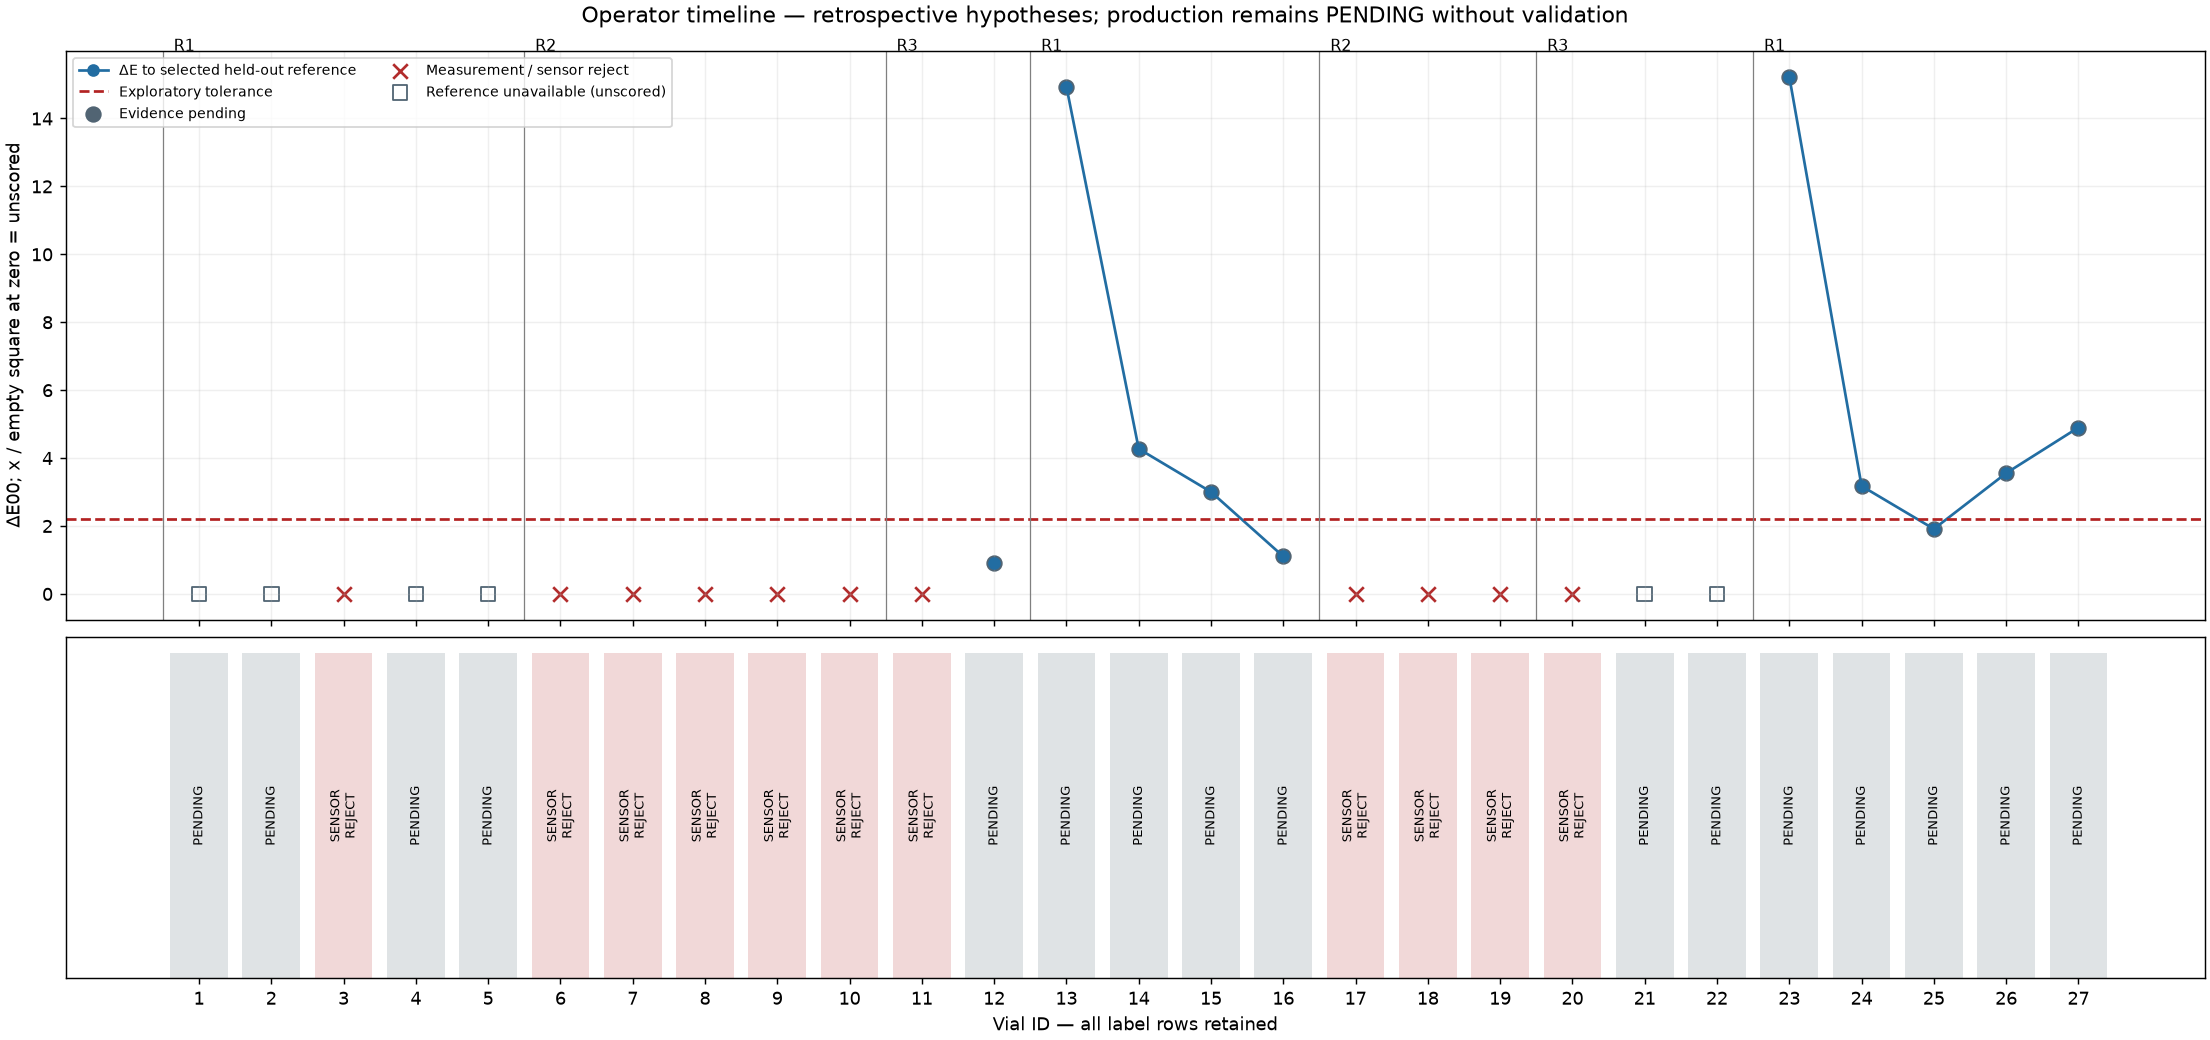

In [7]:
timeline = OUTPUT / 'operator_timeline.png'
if timeline.is_file():
    display(Image(filename=str(timeline), width=1250))
dashboard = OUTPUT / 'operator_dashboard.html'
if dashboard.is_file():
    display(HTML(dashboard.read_text(encoding='utf-8')))


## 7. Evidence gates, exports and interpretation

The original analysis found about **14.94 and 15.23 ΔE00** at the T400 → T100
starts, vials 13 and 23. A high initial difference and later recovery suggest a
process worth investigating; cause attribution still requires trajectory and
reference evidence. A censored run is not assumed to have cleared.

Missing T200 references, clipped channels, short follow-up and one recording
session limit conclusions. The original constrained clean model and carryover
artifacts remain `insufficient_data`. This diagnostic engine does not manufacture
their coefficients, mixture purity, measured fill, a flush recommendation or an
unseen first-vial forecast. Production remains pending until the evidence gates
are met. No pre-fill measurements are used in numerical scoring.

Adding the overhead image reruns A and the paired comparison; it cannot on its
own establish camera transfer accuracy or independent clean ground truth.

In [8]:
display(pd.Series(result['summary']))
display(pd.Series(measured['repeatability']))
display(pd.Series(measured['carryover']))
display(measured['summary'])
display(pd.DataFrame({'artifact': sorted(p.name for p in OUTPUT.iterdir() if p.is_file())}))
print('Exports:', OUTPUT.relative_to(ROOT))
assert result['summary']['prefill_subtraction_applied'] is False
assert result['summary']['root_causes_confirmed'] == 0
if not operator_report.empty:
    assert len(operator_report) == len(measurements)
    assert operator_report['vial_key'].is_unique
    assert operator_report['production_status'].eq('PENDING').all()


status                                                                                                                                                                                 measured
vials                                                                                                                                                                                        27
quality_eligible_vials                                                                                                                                                                       16
diagnostic_states                                                                                                                     {'evidence_pending': 16, 'measurement_sensor_reject': 11}
color_assessments                                                                                   {'unassessable': 17, 'outside_reference_exploratory': 7, 'within_reference_exploratory': 3}
tank_image_status                       

proven                                                                                                                                                                      False
camera_id                                                                                                                                                               vial_fill
calibration_id                                                                                                                                               4b36c670a1f71a29f9f8
threshold                                                                                                                                                                     2.2
budget_delta_e                                                                                                                                                           0.733333
reasons           [Camera calibration has no saved alignment/ROI review acknowledgment., Lock camera settings 

kind                                                                                                                      shared_single_exponential_od
status                                                                                                                               insufficient_data
tau_ml                                                                                                                                            None
tau_interval_ml                                                                                                                                   None
transition_amplitudes_od                                                                                                                            {}
validation                                                                                                                                          []
scope                                                                                         

,transition_id,session_id,previous_recipe_id,next_recipe_id,previous_total_processed_ml,flush_ml,target_source,previous_composition_ml,next_composition_ml,first_vial,...,volume_to_clear_ml,seconds_to_clear,clearance_confirmed_at_vial,volume_to_confirm_ml,low_quality,volume_source,volume_history_usable,recovery_scope,production_status,direction
0,10_29_26/run2,10_29_26,1,2,375.0,NaN,missing,"{'t100_ml': 75.0, 't200_ml': 0.0, 't400_ml': 0.0}","{'t100_ml': 0.0, 't200_ml': 45.0, 't400_ml': 0.0}",6,...,None,None,None,None,True,requested_proxy,False,exploratory_surrogate,PENDING,NaN
1,10_29_26/run3,10_29_26,2,3,225.0,NaN,other_run_tail_surrogate,"{'t100_ml': 0.0, 't200_ml': 45.0, 't400_ml': 0.0}","{'t100_ml': 0.0, 't200_ml': 0.0, 't400_ml': 75.0}",11,...,None,None,None,None,True,requested_proxy,True,exploratory_surrogate,PENDING,unknown
2,10_29_26/run4,10_29_26,3,1,150.0,NaN,other_run_tail_surrogate,"{'t100_ml': 0.0, 't200_ml': 0.0, 't400_ml': 75.0}","{'t100_ml': 75.0, 't200_ml': 0.0, 't400_ml': 0.0}",13,...,None,None,None,None,False,requested_proxy,True,exploratory_surrogate,PENDING,dark_to_light
3,10_29_26/run5,10_29_26,1,2,300.0,NaN,missing,"{'t100_ml': 75.0, 't200_ml': 0.0, 't400_ml': 0.0}","{'t100_ml': 0.0, 't200_ml': 45.0, 't400_ml': 0.0}",17,...,None,None,None,None,True,requested_proxy,True,exploratory_surrogate,PENDING,NaN
4,10_29_26/run6,10_29_26,2,3,135.0,NaN,same_run_tail_surrogate,"{'t100_ml': 0.0, 't200_ml': 45.0, 't400_ml': 0.0}","{'t100_ml': 0.0, 't200_ml': 0.0, 't400_ml': 75.0}",20,...,None,None,None,None,True,requested_proxy,True,exploratory_surrogate,PENDING,unknown
5,10_29_26/run7,10_29_26,3,1,225.0,NaN,other_run_tail_surrogate,"{'t100_ml': 0.0, 't200_ml': 0.0, 't400_ml': 75.0}","{'t100_ml': 75.0, 't200_ml': 0.0, 't400_ml': 0.0}",23,...,None,None,None,None,False,requested_proxy,True,exploratory_surrogate,PENDING,dark_to_light


,artifact
0,alignment_roi_session_1_1.png
1,alignment_roi_session_1_2.png
2,analysis_report.json
3,baseline_comparison.png
4,baseline_metrics.csv
5,baseline_scores.csv
6,baseline_selection.json
7,baseline_tail_provenance.json
8,camera_repeatability.json
9,carryover_model_parameters.json


Exports: outputs/operator_diagnostics/20261101T171246Z_9add185a
